# 02 Classical ML baseline: TF-IDF + Logistic Regression
Word (1-2) and character (2-5, char_wb) TF-IDF n-grams, class-balanced Logistic Regression; Linear SVM and Multinomial NB as extra experiments. Hyper-parameters are tuned by 5-fold stratified CV on the training split only.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)

In [2]:
from src import train_classical
train_classical.main()

logreg       cv=0.9015 val_macroF1=0.9051 phish_recall=0.899 params={'clf__C': 1, 'features__char__ngram_range': (2, 5), 'features__word__ngram_range': (1, 2)} (13s)


linear_svm   cv=0.9073 val_macroF1=0.8816 phish_recall=0.831 params={'clf__C': 0.1} (2s)


naive_bayes  cv=0.8990 val_macroF1=0.8965 phish_recall=0.899 params={'clf__alpha': 0.01} (2s)


{
  "logreg": {
    "best_params": {
      "clf__C": "1",
      "features__char__ngram_range": "(2, 5)",
      "features__word__ngram_range": "(1, 2)"
    },
    "cv_macro_f1": 0.9015,
    "val_macro_f1": 0.9051,
    "val_phishing_recall": 0.8989,
    "grid_search_time_s": 12.6,
    "final_fit_time_s": 0.77
  },
  "linear_svm": {
    "best_params": {
      "clf__C": "0.1"
    },
    "cv_macro_f1": 0.9073,
    "val_macro_f1": 0.8816,
    "val_phishing_recall": 0.8315,
    "grid_search_time_s": 2.5
  },
  "naive_bayes": {
    "best_params": {
      "clf__alpha": "0.01"
    },
    "cv_macro_f1": 0.899,
    "val_macro_f1": 0.8965,
    "val_phishing_recall": 0.8989,
    "grid_search_time_s": 2.1
  }
}


## Test-set evaluation (same held-out test split as the transformer)

In [3]:
res = json.load(open('results/metrics/test_metrics.json'))
from sklearn.metrics import classification_report
for m in ['logreg','naive_bayes','linear_svm']:
    o = res[m]['overall']
    print(f"{res[m]['display_name']:32s} acc={o['accuracy']:.4f} macroF1={o['macro_f1']:.4f} phishing recall={o['per_class']['phishing']['recall']:.3f} Hinglish macroF1={res[m]['hinglish']['macro_f1']:.3f}")

TF-IDF + Logistic Regression     acc=0.9651 macroF1=0.8937 phishing recall=0.892 Hinglish macroF1=0.846
TF-IDF + Multinomial NB          acc=0.9651 macroF1=0.8957 phishing recall=0.904 Hinglish macroF1=0.884
TF-IDF + Linear SVM              acc=0.9672 macroF1=0.8933 phishing recall=0.880 Hinglish macroF1=0.880


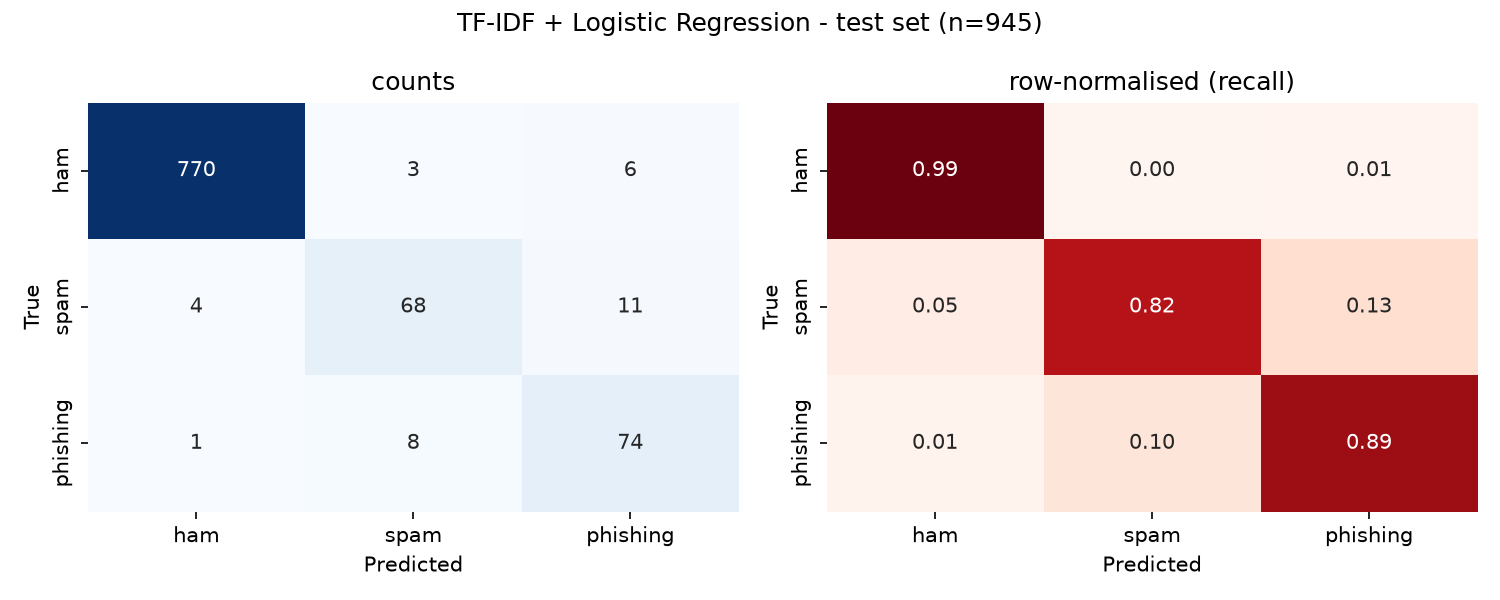

In [4]:
display(Image('results/confusion_matrices/cm_logreg.png', width=800))

## Most informative n-grams per class

In [5]:
import joblib, numpy as np
pipe = joblib.load('models/classical/logreg.joblib')
names = pipe.named_steps['features'].get_feature_names_out(); clf = pipe.named_steps['clf']
for i, c in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[::-1][:15]
    print(c.upper(), ':', ', '.join(names[j].split('__',1)[1] for j in top))

HAM : i, my,  i ,  i, it, but, i , ok, da, i'm, got, k, come, he, ? 
PHISHING : <phone>, <url>, claim, urgent, > ,  <, <phone> now, you have,  <ph, ne>, <pho,  <pho, <ph,  <p, hone>
SPAM : to <num>, free, text, <num>, xt, 2, karo, 1, sms, noida, sirf, <phone>,  1, with, win


## Predictions on the demo messages (synthetic examples)

In [6]:
from src.predict import load_predictor
from src.explainability import logreg_top_features
p = load_predictor('logreg')
msgs = ['Your appointment is confirmed for tomorrow at 10 AM.', 'Congratulations! You have won a free gift. Claim now.',
        'Your bank account will be blocked today. Update KYC immediately using this link.',
        'Aapka SBI account band ho jayega. KYC update karne ke liye abhi link open karo.',
        'Kal college lecture 10 baje hai, time pe aa jana.']
for m, r in zip(msgs, p.predict(msgs)):
    print(f"[{r['label']:8s} {r['confidence']:.2f}] {m}\n     top n-grams: {logreg_top_features(p.pipe, m, r['label'], 4)}")

[ham      0.83] Your appointment is confirmed for tomorrow at 10 AM.
     top n-grams: [('appointment (word)', 0.043), ('tomorrow (word)', 0.041), ('orr (chars)', 0.011), ('confirmed (word)', 0.011)]
[phishing 0.90] Congratulations! You have won a free gift. Claim now.
     top n-grams: [('claim (word)', 0.368), ('you have (word)', 0.296), ('won (word)', 0.247), ('have won (word)', 0.154)]


[phishing 0.71] Your bank account will be blocked today. Update KYC immediately using this link.
     top n-grams: [('link (word)', 0.224), ('account (word)', 0.132), ('update (word)', 0.128), ('this link (word)', 0.115)]


[phishing 0.96] Aapka SBI account band ho jayega. KYC update karne ke liye abhi link open karo.
     top n-grams: [('link (word)', 0.19), ('aapka (word)', 0.113), ('karne ke (word)', 0.113), ('karne (word)', 0.113)]
[ham      0.91] Kal college lecture 10 baje hai, time pe aa jana.
     top n-grams: [('kal (word)', 0.045), ('baje (word)', 0.035), ('college (word)', 0.027), ('hai time (word)', 0.027)]
